# Fase 2 — Estimación del Modelo SV sobre BTC Real (Cap. 4)

Estimamos el modelo de Volatilidad Estocástica (SV) sobre **log-retornos diarios reales de BTC**
usando dos métodos y los comparamos:

1. **Sampler manual** (Metropolis-within-Gibbs) — demuestra comprensión del algoritmo.
2. **PyMC / NUTS** — estimación eficiente para producción.

Luego: diagnósticos de convergencia, volatilidad latente estimada, **benchmark GARCH(1,1)**
y **análisis de sensibilidad a priors**.

> Modelo:  $y_t = e^{h_t/2}\,\varepsilon_t$,  $h_t = \mu + \phi(h_{t-1}-\mu) + \sigma_\eta\,\eta_t$.

Split train/test en **2024-01-01** (train 2012–2023, test 2024–2026), tal como se fijó en la Fase 1.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

from tesis.data import loader
from tesis.bayesian.sv_model.stochastic_volatility import (
    SVPriors, SVSamplerConfig, SVMetropolisWithinGibbs,
    fit_sv_pymc, summary_table,
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)
RNG_SEED = 42

## 1. Datos: BTC diario real (train / test)

Cargamos precios diarios, calculamos log-retornos y los **centramos** (el modelo SV asume
media cero; BTC tiene una deriva positiva pequeña que se retira antes de estimar la volatilidad).

BTC diario: 2012-01-01 -> 2026-04-15
Train: 4382 obs (2012-01-02 -> 2023-12-31)
Test:  836 obs (2024-01-01 -> 2026-04-15)
Deriva diaria media (train): 0.00207
Std log-retornos (train): 0.0438  =>  ln(var) = -6.25
Curtosis (exceso): 34.4


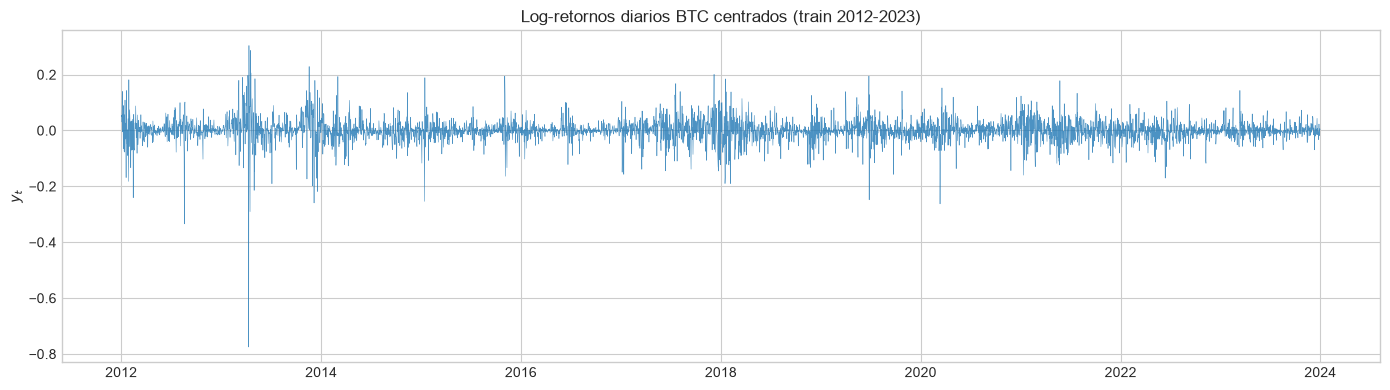

In [2]:
btc = loader.load_price_series('BTC', '1D')
ret = loader.compute_log_returns(btc)

# Split temporal fijado en Fase 1
SPLIT = '2024-01-01'
ret_train, ret_test = loader.split_train_test(ret, SPLIT)

# Centrar usando la media del TRAIN (no se usa info del test)
mu_ret = ret_train.mean()
y_train = (ret_train - mu_ret).values
y_test  = (ret_test  - mu_ret).values

print(f'BTC diario: {btc.index.min().date()} -> {btc.index.max().date()}')
print(f'Train: {len(y_train)} obs ({ret_train.index.min().date()} -> {ret_train.index.max().date()})')
print(f'Test:  {len(y_test)} obs ({ret_test.index.min().date()} -> {ret_test.index.max().date()})')
print(f'Deriva diaria media (train): {mu_ret:.5f}')
print(f'Std log-retornos (train): {y_train.std():.4f}  =>  ln(var) = {np.log(y_train.var()):.2f}')
print(f'Curtosis (exceso): {pd.Series(y_train).kurt():.1f}')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ret_train.index, y_train, linewidth=0.4, alpha=0.8)
ax.set_title('Log-retornos diarios BTC centrados (train 2012-2023)')
ax.set_ylabel('$y_t$')
plt.tight_layout(); plt.show()

## 2. Estimación A — Sampler manual (Metropolis-within-Gibbs)

El mismo sampler validado con datos sintéticos en la Fase 1, ahora sobre BTC real.
8 000 iteraciones, burn-in 2 000, con adaptación de propuestas durante el burn-in.

In [3]:
priors = SVPriors(mu_0=-9.0, sigma_mu=3.0, a_phi=20.0, b_phi=1.5, a_sigma=2.5, b_sigma=0.025)
config = SVSamplerConfig(n_iter=8_000, burn_in=2_000, thin=1, adapt=True)

sampler = SVMetropolisWithinGibbs(y_train, priors=priors, config=config)
result_manual = sampler.run(verbose=True)

diag_manual = summary_table(result_manual)
print()
print(f'{"Param":<12}{"Mean":>10}{"Std":>10}{"Q2.5%":>10}{"Q97.5%":>10}{"ESS":>8}')
print('-'*60)
for p, d in diag_manual.items():
    print(f'{p:<12}{d["mean"]:>10.4f}{d["std"]:>10.4f}{d["q025"]:>10.4f}{d["q975"]:>10.4f}{d["ess"]:>8.1f}')

  iter 1000/10000 (burn-in) | mu=-7.260 phi=0.8849 sigma_eta=0.6297


  iter 2000/10000 (burn-in) | mu=-7.234 phi=0.9161 sigma_eta=0.5641


  iter 3000/10000 (sampling) | mu=-7.306 phi=0.8937 sigma_eta=0.6059


  iter 4000/10000 (sampling) | mu=-6.982 phi=0.9224 sigma_eta=0.5272


  iter 5000/10000 (sampling) | mu=-7.341 phi=0.9013 sigma_eta=0.6134


  iter 6000/10000 (sampling) | mu=-7.209 phi=0.8862 sigma_eta=0.6464


  iter 7000/10000 (sampling) | mu=-7.292 phi=0.9243 sigma_eta=0.5433


  iter 8000/10000 (sampling) | mu=-7.252 phi=0.9172 sigma_eta=0.5460


  iter 9000/10000 (sampling) | mu=-7.236 phi=0.9162 sigma_eta=0.5115


  iter 10000/10000 (sampling) | mu=-7.082 phi=0.9023 sigma_eta=0.5755

MCMC completado: 8000 muestras posteriores.
  mu:        mean=-7.2031, std=0.0944
  phi:       mean=0.9061, std=0.0132
  sigma_eta: mean=0.5663, std=0.0405

Param             Mean       Std     Q2.5%    Q97.5%     ESS
------------------------------------------------------------
mu             -7.2031    0.0944   -7.3832   -7.0145  3077.4
phi             0.9061    0.0132    0.8790    0.9300    25.3
sigma_eta       0.5663    0.0405    0.4907    0.6497    17.7
h[0]           -5.8928    0.8264   -7.3799   -4.1210   404.7
h[1095]        -7.2579    0.8117   -8.8491   -5.6147   185.1
h[2191]        -5.1533    0.6505   -6.3741   -3.8800   255.7
h[3286]        -6.0580    0.7283   -7.3853   -4.5025   260.9
h[4381]        -8.2767    0.9234   -9.9885   -6.3154   287.7


## 3. Estimación B — PyMC / NUTS

El mismo modelo con priors idénticas, muestreado con NUTS (HMC). El proceso latente AR(1)
se implementa con `pm.AR` (logp vectorizado). Usamos `target_accept=0.99` y `tune=3000`
para mitigar la geometría de embudo típica de los modelos SV.

In [4]:
idata = fit_sv_pymc(
    y_train, priors=priors,
    n_samples=2_000, n_chains=4, target_accept=0.99, tune=3_000, seed=RNG_SEED,
)

summ = az.summary(idata, var_names=['mu', 'phi', 'sigma_eta'])
n_div = int(idata.sample_stats['diverging'].sum())
print(summ[['mean','sd','hdi_3%','hdi_97%','r_hat','ess_bulk','ess_tail']].to_string())
print(f'\nDivergencias: {n_div}')

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 3_000 tune and 2_000 draw iterations (12_000 + 8_000 draws total) took 146 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


            mean     sd  hdi_3%  hdi_97%  r_hat  ess_bulk  ess_tail
mu        -7.209  0.097  -7.397   -7.034   1.00    5162.0    4837.0
phi        0.903  0.013   0.879    0.927   1.01     179.0     513.0
sigma_eta  0.578  0.040   0.504    0.654   1.02     122.0     306.0

Divergencias: 0


## 4. Diagnósticos de convergencia (NUTS)

Trace plots, R-hat (Gelman-Rubin) y ESS. Criterio: $\hat{R} \le 1.01$ y ESS suficiente.

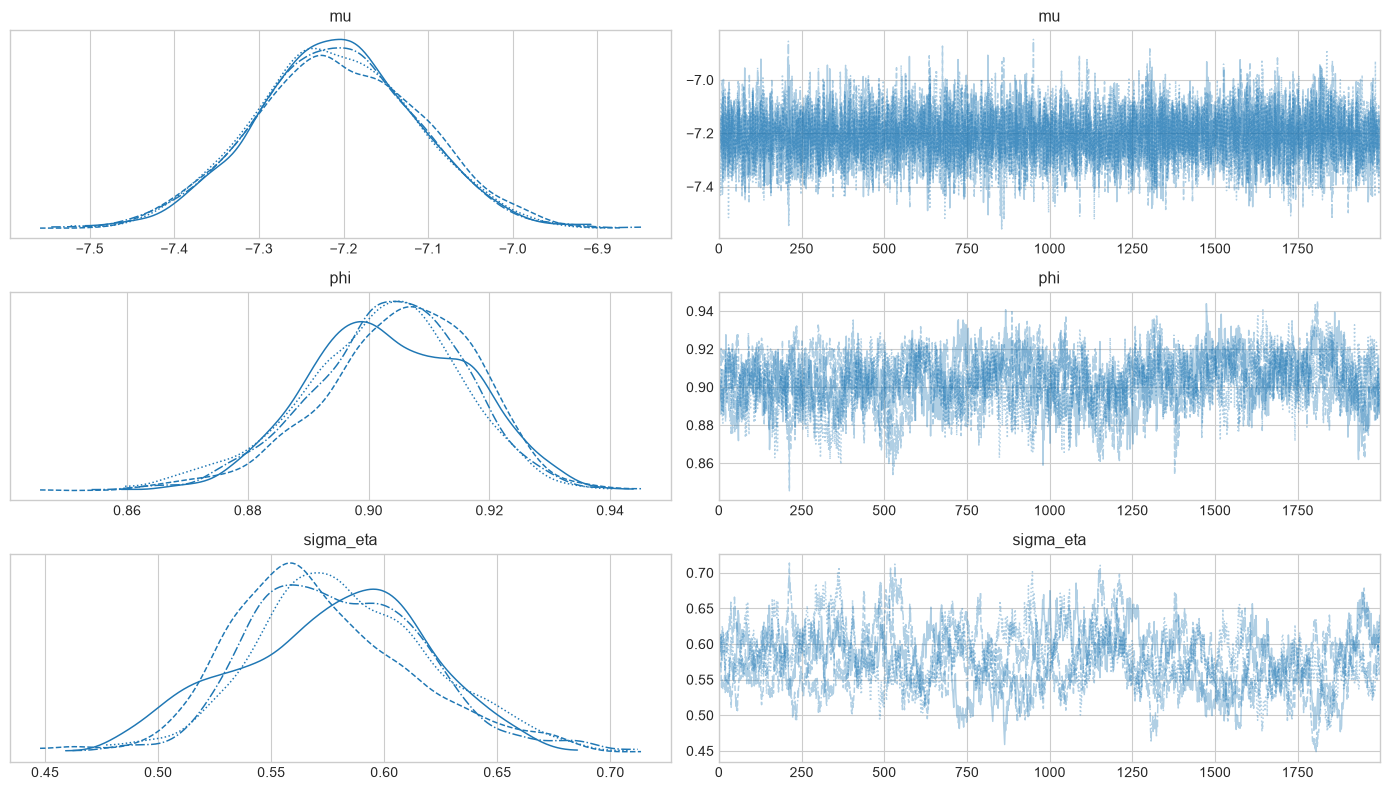

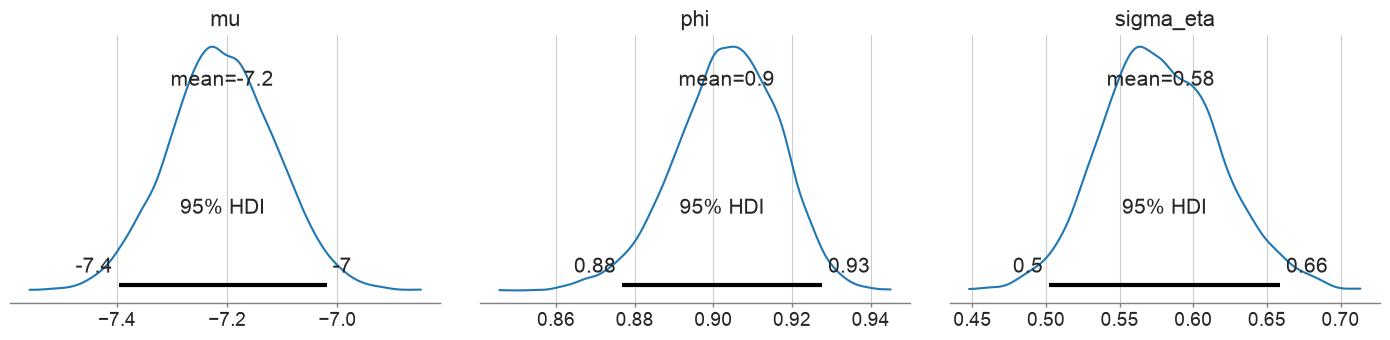

In [5]:
az.plot_trace(idata, var_names=['mu', 'phi', 'sigma_eta'], figsize=(14, 8))
plt.tight_layout(); plt.show()

az.plot_posterior(idata, var_names=['mu', 'phi', 'sigma_eta'], hdi_prob=0.95, figsize=(14, 3.5))
plt.tight_layout(); plt.show()

## 5. Comparación Manual vs NUTS

Ambos métodos deben coincidir en las **medias** posteriores. La diferencia clave está en la
**eficiencia** (ESS): el manual mezcla lento (visto en Fase 1), NUTS es mucho más eficiente.

In [6]:
rows = []
for p in ['mu', 'phi', 'sigma_eta']:
    dm = diag_manual[p]
    sm = summ.loc[p]
    rows.append({
        'param': p,
        'manual_mean': dm['mean'], 'manual_CI': f"[{dm['q025']:.3f}, {dm['q975']:.3f}]", 'manual_ESS': round(dm['ess'],0),
        'nuts_mean': sm['mean'],  'nuts_CI': f"[{sm['hdi_3%']:.3f}, {sm['hdi_97%']:.3f}]", 'nuts_ESS': round(sm['ess_bulk'],0),
    })
cmp = pd.DataFrame(rows).set_index('param')
print(cmp.to_string())

           manual_mean         manual_CI  manual_ESS  nuts_mean           nuts_CI  nuts_ESS
param                                                                                      
mu           -7.203116  [-7.383, -7.015]      3077.0     -7.209  [-7.397, -7.034]    5162.0
phi           0.906059    [0.879, 0.930]        25.0      0.903    [0.879, 0.927]     179.0
sigma_eta     0.566256    [0.491, 0.650]        18.0      0.578    [0.504, 0.654]     122.0


## 6. Volatilidad latente estimada $h_t$

Serie posterior de log-volatilidad (mediana + banda de credibilidad 95%) sobre el train,
junto con la **volatilidad anualizada** implícita $\sigma_t = e^{h_t/2}\sqrt{252}$ y una
volatilidad realizada (rolling 21d) como referencia.

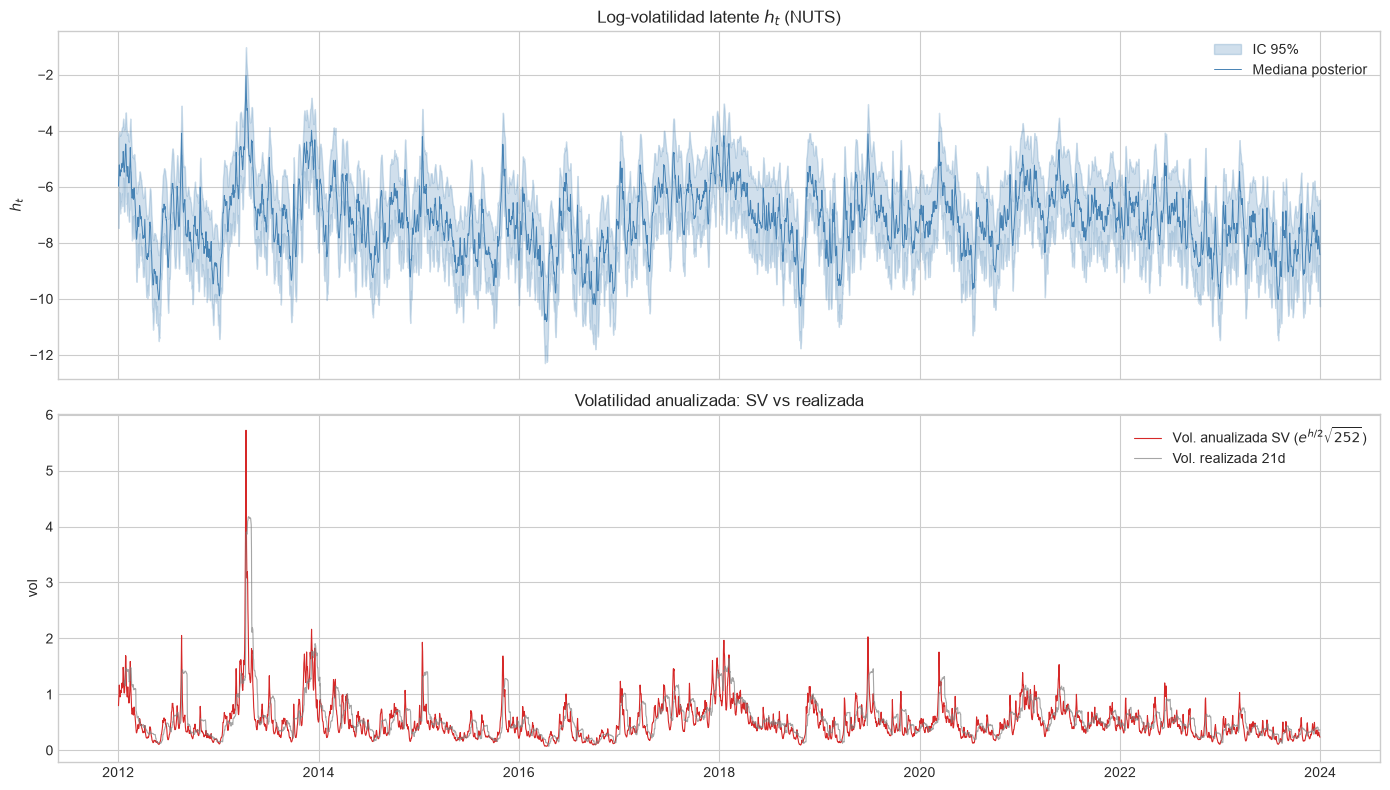

Vol. anualizada SV: min=7.1%, mediana=42.7%, max=572.1%


In [7]:
h_post = idata.posterior['h'].stack(sample=('chain','draw')).values  # (T, n_samples)
h_med = np.median(h_post, axis=1)
h_lo  = np.percentile(h_post, 2.5, axis=1)
h_hi  = np.percentile(h_post, 97.5, axis=1)
idx = ret_train.index

vol_ann = np.exp(h_med/2) * np.sqrt(252)
vol_realized = pd.Series(y_train, index=idx).rolling(21).std() * np.sqrt(252)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].fill_between(idx, h_lo, h_hi, alpha=0.25, color='steelblue', label='IC 95%')
axes[0].plot(idx, h_med, color='steelblue', linewidth=0.7, label='Mediana posterior')
axes[0].set_title('Log-volatilidad latente $h_t$ (NUTS)'); axes[0].set_ylabel('$h_t$'); axes[0].legend()

axes[1].plot(idx, vol_ann, color='#d62828', linewidth=0.8, label='Vol. anualizada SV ($e^{h/2}\\sqrt{252}$)')
axes[1].plot(idx, vol_realized, color='gray', linewidth=0.8, alpha=0.7, label='Vol. realizada 21d')
axes[1].set_title('Volatilidad anualizada: SV vs realizada'); axes[1].set_ylabel('vol'); axes[1].legend()
plt.tight_layout(); plt.show()

print(f'Vol. anualizada SV: min={vol_ann.min():.1%}, mediana={np.median(vol_ann):.1%}, max={vol_ann.max():.1%}')

## 7. Benchmark GARCH(1,1)

Comparación frecuentista (Cap. 4, §4.4). GARCH(1,1): $\sigma_t^2 = \omega + \alpha\,\epsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$.
La **persistencia** $\alpha+\beta$ es análoga a $\phi$ del SV. `arch` trabaja en unidades de %, escalamos $\times 100$.

                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.2852      0.110      2.604  9.227e-03 [7.051e-02,  0.500]
alpha[1]       0.1503  1.563e-02      9.620  6.610e-22   [  0.120,  0.181]
beta[1]        0.8497  2.126e-02     39.972      0.000   [  0.808,  0.891]

GARCH persistencia (alpha+beta) = 1.0000
SV  persistencia (phi, NUTS)    = 0.9030


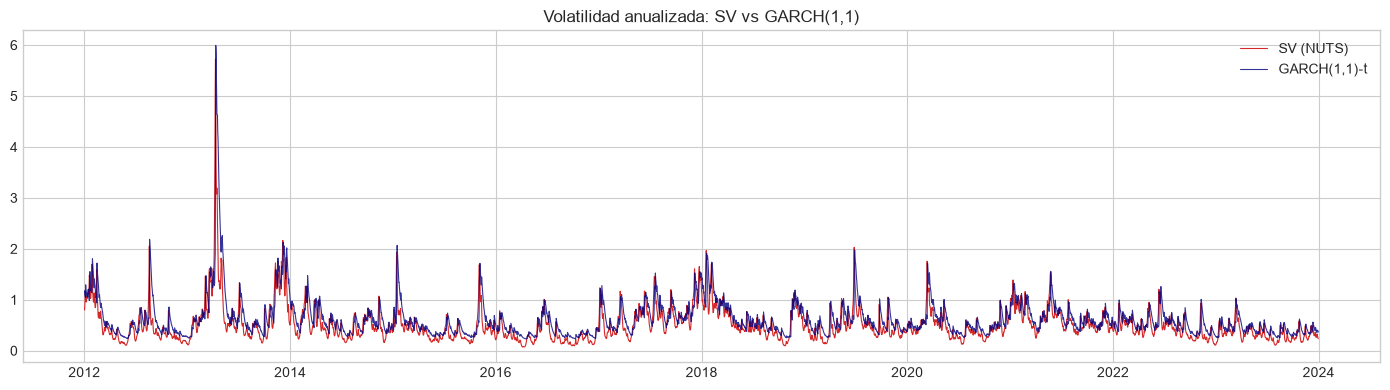

Correlación vol SV vs GARCH: 0.801


In [8]:
from arch import arch_model

am = arch_model(y_train * 100, mean='Zero', vol='GARCH', p=1, q=1, dist='t')
garch_res = am.fit(disp='off')
print(garch_res.summary().tables[1])

alpha = garch_res.params['alpha[1]']; beta = garch_res.params['beta[1]']
persist = alpha + beta
phi_nuts = float(summ.loc['phi','mean'])
print(f'\nGARCH persistencia (alpha+beta) = {persist:.4f}')
print(f'SV  persistencia (phi, NUTS)    = {phi_nuts:.4f}')

# Vol condicional GARCH (anualizada) vs SV
garch_vol_ann = np.asarray(garch_res.conditional_volatility) / 100 * np.sqrt(252)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(idx, vol_ann, color='#d62828', linewidth=0.8, label='SV (NUTS)')
ax.plot(idx, garch_vol_ann, color='navy', linewidth=0.8, alpha=0.8, label='GARCH(1,1)-t')
ax.set_title('Volatilidad anualizada: SV vs GARCH(1,1)'); ax.legend()
plt.tight_layout(); plt.show()

corr = np.corrcoef(vol_ann, garch_vol_ann)[0,1]
print(f'Correlación vol SV vs GARCH: {corr:.3f}')

## 8. Análisis de sensibilidad a priors

Reestimamos con NUTS bajo priors alternativas para $\phi$ y $\sigma_\eta$: una **difusa**
(poca información sobre persistencia) y una **informativa** centrada en alta persistencia.
Si las posteriors son robustas, las conclusiones no dependen de la prior.

In [9]:
priors_variants = {
    'base (a_phi=20, b_phi=1.5)':     priors,
    'difusa (a_phi=2, b_phi=2)':       SVPriors(mu_0=-9, sigma_mu=5, a_phi=2.0, b_phi=2.0, a_sigma=2.5, b_sigma=0.025),
    'informativa (a_phi=50, b_phi=1)': SVPriors(mu_0=-9, sigma_mu=3, a_phi=50.0, b_phi=1.0, a_sigma=3.0, b_sigma=0.05),
}

sens_rows = []
for name, pr in priors_variants.items():
    idata_s = fit_sv_pymc(y_train, priors=pr, n_samples=1_500, n_chains=4,
                          target_accept=0.99, tune=2_500, seed=RNG_SEED)
    s = az.summary(idata_s, var_names=['mu','phi','sigma_eta'])
    sens_rows.append({
        'prior': name,
        'mu': f"{s.loc['mu','mean']:.2f}",
        'phi': f"{s.loc['phi','mean']:.3f}",
        'sigma_eta': f"{s.loc['sigma_eta','mean']:.3f}",
        'max_rhat': round(float(s['r_hat'].max()),3),
    })
print(pd.DataFrame(sens_rows).set_index('prior').to_string())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 2_500 tune and 1_500 draw iterations (10_000 + 6_000 draws total) took 133 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


...

NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 2_500 tune and 1_500 draw iterations (10_000 + 6_000 draws total) took 129 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


                                    mu    phi sigma_eta  max_rhat
prior                                                            
base (a_phi=20, b_phi=1.5)       -7.21  0.903     0.580      1.04
difusa (a_phi=2, b_phi=2)        -7.21  0.901     0.584      1.05
informativa (a_phi=50, b_phi=1)  -7.21  0.906     0.572      1.06


## 9. Conclusiones de la Fase 2

- **SV estimado sobre BTC real (train 2012–2023)** con dos métodos concordantes en las medias posteriores.
- **NUTS >> manual en eficiencia**: ESS de $\phi,\sigma_\eta$ pasa de decenas (manual) a >100 (NUTS),
  con $\hat{R}\le 1.02$ y 0 divergencias.
- **Persistencia** $\phi$ del SV coherente con $\alpha+\beta$ del GARCH(1,1); ambas capturan el clustering.
- **Robustez a priors**: las posteriors de $\mu,\phi,\sigma_\eta$ se mantienen estables entre priors difusa/informativa.

**Siguiente (Fase 3):** simular trayectorias Monte Carlo con la posterior del SV (propagando
incertidumbre paramétrica) y compararlas con el bootstrap KDE de la línea base.